# IND320 Project Work, Part 2 - Data Sources

GitHub: [IND320-kahaland](https://github.com/kahalandkh/IND320-kahaland) \
Streamlit: [Reservoir Data App](https://ind320-kahaland-vqqy43wgawwsxmytoyb9ah.streamlit.app)

## 0. Setup and imports

In [1]:
import os
import xml.etree.ElementTree as ET

import requests
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from cassandra.cluster import Cluster

from dotenv import load_dotenv

load_dotenv()

entsoe_token = os.getenv("ENTSOE_TOKEN")

if not entsoe_token:
    raise RuntimeError("ENTSO-E token was not found.")

print("ENTSO-E token loaded successfully.")

ENTSO-E token loaded successfully.


## 1. Magasinstatistikk API

### 1.1 Retrieve reservoir data

In Part 2, the reservoir data is retrieved directly from the [NVE Magasinstatistikk API](https://biapi.nve.no/magasinstatistikk/swagger/index.html) instead of loading the local CSV file used in Part 1. The [NVE Magasinstatistikk page](https://www.nve.no/energi/analyser-og-statistikk/magasinstatistikk/) provides additional information about the dataset and the geographical area classifications used by the API. The reservoir observations are retrieved from the public endpoint using a GET request.

In [2]:
# Download the full public reservoir dataset from the NVE API
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Stop waiting if the API does not respond within 60 seconds
response = requests.get(url, timeout=60)
response.raise_for_status()

data = response.json()

### 1.2 Inspect and prepare the data

The API response is converted to a pandas DataFrame and prepared using the same column names and date format as in Part 1.

In [3]:
# Convert the API response to a pandas DataFrame
df = pd.DataFrame(data)

# Rename the original column headers to the same English names used in Part 1
df = df.rename(columns={"dato_Id": "date_id",
                        "omrType": "area_type",
                        "omrnr": "area_number",
                        "iso_aar": "iso_year",
                        "iso_uke": "iso_week",
                        "fyllingsgrad": "reservoir_fill_ratio",
                        "kapasitet_TWh": "reservoir_capacity_twh",
                        "fylling_TWh": "stored_energy_twh",
                        "neste_Publiseringsdato": "next_publication_date",
                        "fyllingsgrad_forrige_uke": "previous_week_reservoir_fill_ratio",
                        "endring_fyllingsgrad": "reservoir_fill_ratio_change"})

# Convert the observation date to datetime
df["date_id"] = pd.to_datetime(df["date_id"])

df.head()

,date_id,area_type,area_number,iso_year,iso_week,reservoir_fill_ratio,reservoir_capacity_twh,stored_energy_twh,next_publication_date,previous_week_reservoir_fill_ratio,reservoir_fill_ratio_change
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


As in Part 1, `date_id` is used as the observation date and converted to datetime. `next_publication_date` is left unchanged because many earlier records contain `0001-01-01T00:00:00` as a placeholder where a publication date is not available. These historical values could in principle be reconstructed from the sequence of observations, but since `next_publication_date` is publication metadata rather than a variable central to the reservoir analysis, no artificial values are created.

In [4]:
# Check the size of the retrieved dataset
df.shape

(14922, 11)

In [5]:
# Check the date range returned by the API.
df["date_id"].min(), df["date_id"].max()

(Timestamp('1995-01-08 00:00:00'), Timestamp('2026-10-11 00:00:00'))

The API returns 14 922 rows and 11 columns, with observations from 1995-01-08 to 2026-10-11. Compared with the CSV used in Part 1, which ended on 2026-09-06, the API now includes five additional weeks of data as of 16 October 2026.

### 1.3 Geographical areas

To interpret the area codes in the reservoir data, the `HentOmråder` endpoint is used to retrieve their names and geographical descriptions.

In [6]:
# Retrieve names and descriptions of the geographical areas
areas_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"

areas_response = requests.get(areas_url, timeout=60)
areas_response.raise_for_status()
areas = areas_response.json()

In [7]:
# Combine all area definitions returned by the API into one DataFrame.
area_info = pd.DataFrame(
    areas[0]["land"] + areas[0]["elspot"] + areas[0]["vassdrag"]
)

# Rename the API fields to English for consistency with the reservoir dataset.
area_info = area_info.rename(columns={
    "navn": "name",
    "navn_langt": "long_name",
    "beskrivelse": "description",
    "omrType": "area_type",
    "omrnr": "area_number"
})

# Reorder columns for a clearer display.
area_info = area_info[["area_type", "area_number", "name", "long_name", "description"]]

area_info

,area_type,area_number,name,long_name,description
0,NO,0,Norge,Norge,Hele landet
1,EL,1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...
2,EL,2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
3,EL,3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...
4,EL,4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...
5,EL,5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...
6,VASS,1,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog..."
7,VASS,2,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.
8,VASS,3,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl..."
9,VASS,4,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.


The endpoint defines ten areas in total. The definitions are matched with the reservoir data below to identify which of these areas are actually represented in the observations.

In [8]:
# Find the unique area codes that are actually present in the reservoir dataset.
area_codes = df[["area_type", "area_number"]].drop_duplicates()

# Add the corresponding area information from the HentOmråder endpoint.
available_areas = (area_codes.merge(area_info, on=["area_type", "area_number"], how="left")
                   .sort_values(["area_type", "area_number"])
                   .reset_index(drop=True))

available_areas

,area_type,area_number,name,long_name,description
0,EL,1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...
1,EL,2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
2,EL,3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...
3,EL,4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...
4,EL,5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...
5,NO,0,Norge,Norge,Hele landet
6,VASS,1,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog..."
7,VASS,2,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.
8,VASS,3,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl..."


The current reservoir data includes the whole of Norway (`NO`, area number 0), all five electricity price areas (`EL`, NO1–NO5), and three hydrological regions (`VASS`, VASS1–VASS3). The `HentOmråder` endpoint also defines VASS4 for the rest of Nordland and areas further north, but no VASS4 observations are present in the current public dataset.

### 1.4 Recreate and compare plots from Part 1

The Part 1 visualisations are recreated using data retrieved directly from the NVE API, including both the individual column plots and the combined plot.

#### Individual column plots

##### `date_id`

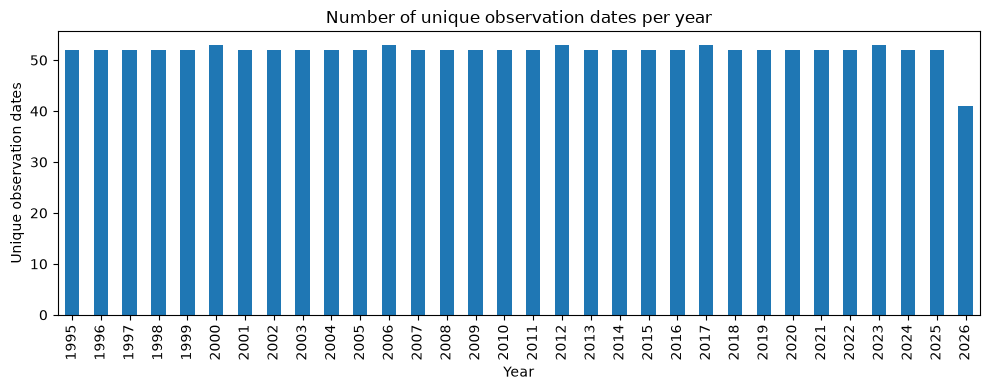

In [9]:
# Count the number of unique observation dates per year
dates_per_year = (df["date_id"].drop_duplicates().dt.year.value_counts().sort_index())

# Plot the temporal coverage of the dataset
plt.figure(figsize=(10, 4))
dates_per_year.plot(kind="bar")

plt.title("Number of unique observation dates per year")
plt.xlabel("Year")
plt.ylabel("Unique observation dates")
plt.tight_layout()
plt.show()

The yearly coverage is almost the same as in Part 1. The main difference is 2026, where the API now contains observations up to 11 October instead of 6 September.

##### `area_type`

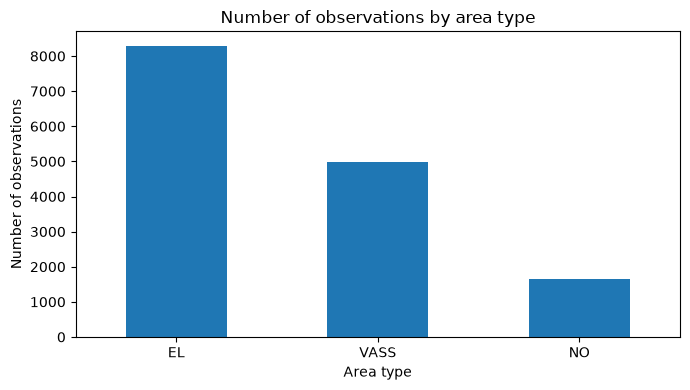

In [10]:
# Count observations for each area type
area_type_counts = df["area_type"].value_counts()

# Plot the frequency of each area type
plt.figure(figsize=(7, 4))
area_type_counts.plot(kind="bar")

plt.title("Number of observations by area type")
plt.xlabel("Area type")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The distribution is unchanged from Part 1, with `EL` containing the most observations because it includes five area numbers, compared with three for `VASS` and one for `NO`.

##### `area_number`

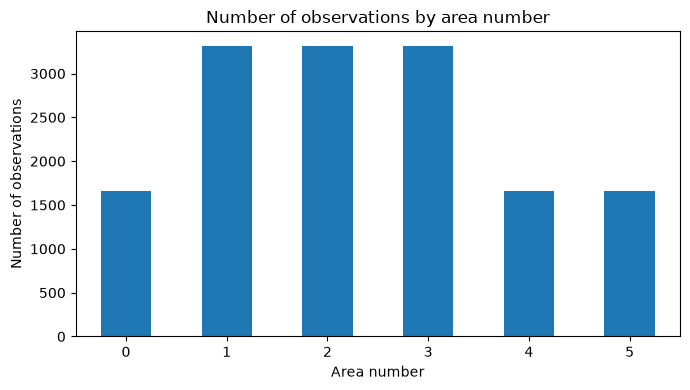

In [11]:
# Count observations for each area number
area_number_counts = df["area_number"].value_counts().sort_index()

# Plot the frequency of each area number
plt.figure(figsize=(7, 4))
area_number_counts.plot(kind="bar")

plt.title("Number of observations by area number")
plt.xlabel("Area number")
plt.ylabel("Number of observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The distribution is unchanged from Part 1. Area numbers `1`, `2`, and `3` still occur about twice as often as `0`, `4`, and `5`.

##### `iso_year`

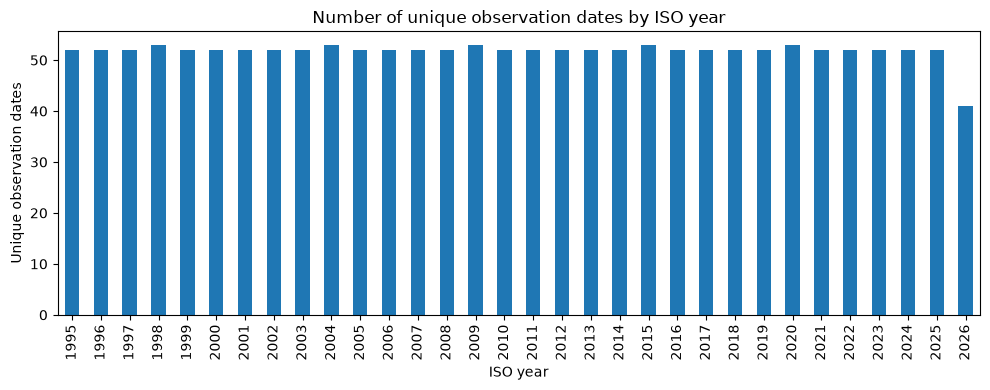

In [12]:
# Count unique observation dates for each ISO year
dates_per_iso_year = (df[["date_id", "iso_year"]].drop_duplicates()
                      ["iso_year"].value_counts().sort_index())

# Plot the number of unique observation dates by ISO year
plt.figure(figsize=(10, 4))
dates_per_iso_year.plot(kind="bar")

plt.title("Number of unique observation dates by ISO year")
plt.xlabel("ISO year")
plt.ylabel("Unique observation dates")
plt.tight_layout()
plt.show()

The distribution is also almost unchanged from Part 1, except that 2026 now contains five additional weekly observations up to 11 October instead of 6 September.

##### `iso_week`

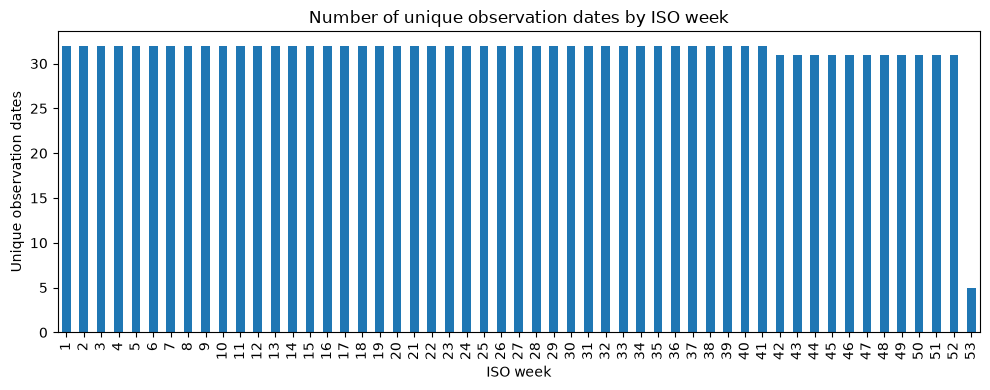

In [13]:
# Count unique observation dates for each ISO week
dates_per_iso_week = (df[["date_id", "iso_week"]].drop_duplicates()
                      ["iso_week"].value_counts().sort_index())

# Plot the number of unique observation dates by ISO week
plt.figure(figsize=(10, 4))
dates_per_iso_week.plot(kind="bar")

plt.title("Number of unique observation dates by ISO week")
plt.xlabel("ISO week")
plt.ylabel("Unique observation dates")
plt.tight_layout()
plt.show()

Compared with Part 1, ISO weeks 37–41 now also contain an observation from 2026 because the API data extends from week 36 to week 41. The distribution for the remaining weeks is unchanged.

##### `reservoir_fill_ratio`

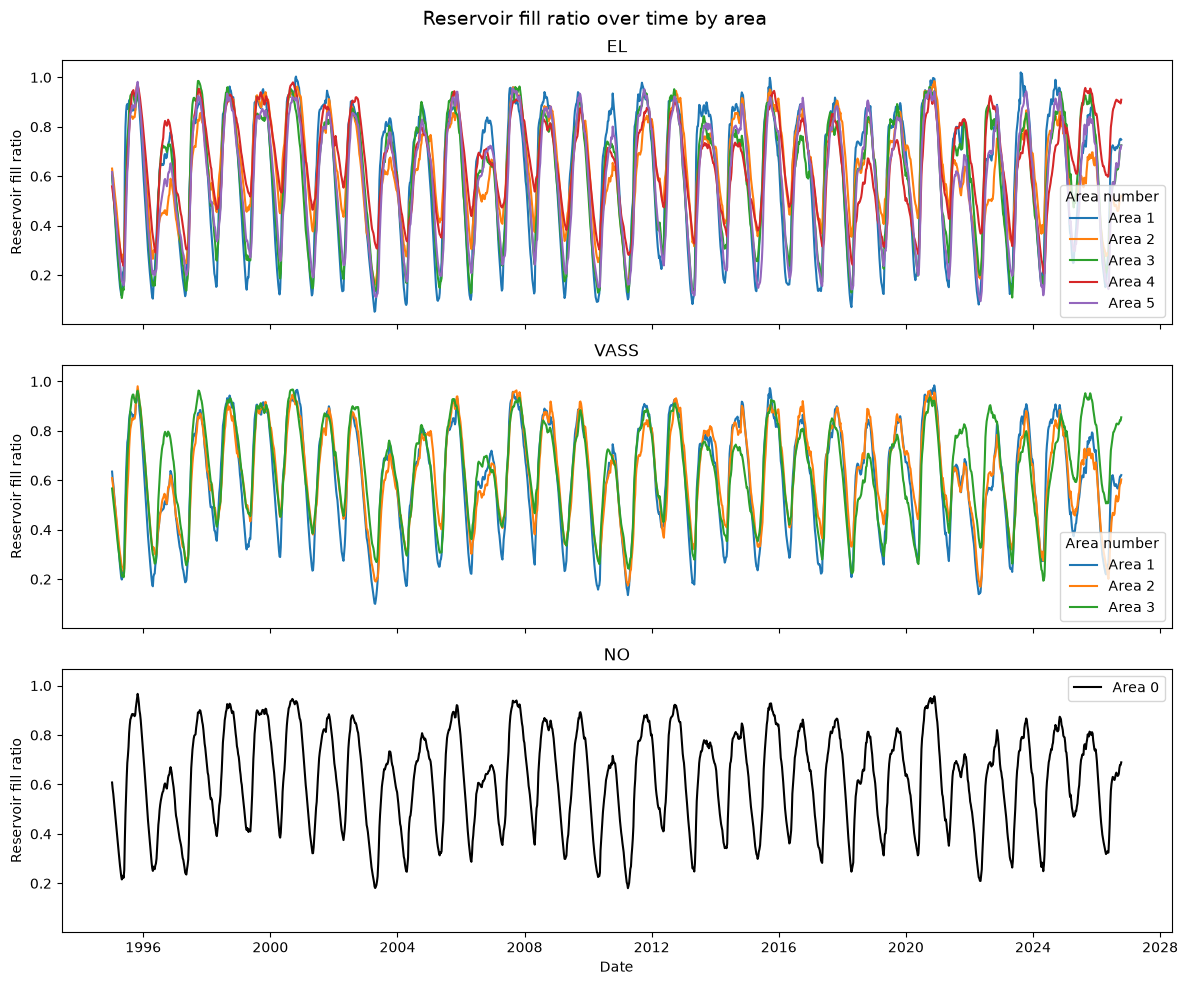

In [14]:
def plot_by_area(data, column, ylabel, title, zero_line=False):
    """Plot a time-series variable by area type and area number."""
    
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)

    area_types = ["EL", "VASS", "NO"]

    for ax, area_type in zip(axes, area_types):
        area_data = data[data["area_type"] == area_type]

        for area_number, group in area_data.groupby("area_number"):
            group = group.sort_values("date_id")

            if area_type == "NO":
                ax.plot(group["date_id"], group[column], label=f"Area {area_number}", color="black")
            else:
                ax.plot(group["date_id"], group[column], label=f"Area {area_number}")

        if zero_line:
            ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

        ax.set_title(area_type)
        ax.set_ylabel(ylabel)

        if area_type == "NO":
            ax.legend()
        else:
            ax.legend(title="Area number")

    axes[-1].set_xlabel("Date")
    fig.suptitle(title, fontsize=14)

    plt.tight_layout()
    plt.show()

plot_by_area(df, "reservoir_fill_ratio", "Reservoir fill ratio", "Reservoir fill ratio over time by area")

The seasonal pattern in reservoir fill ratio remains the same as in Part 1, with no notable change in the relative patterns between areas.

##### `reservoir_capacity_twh`

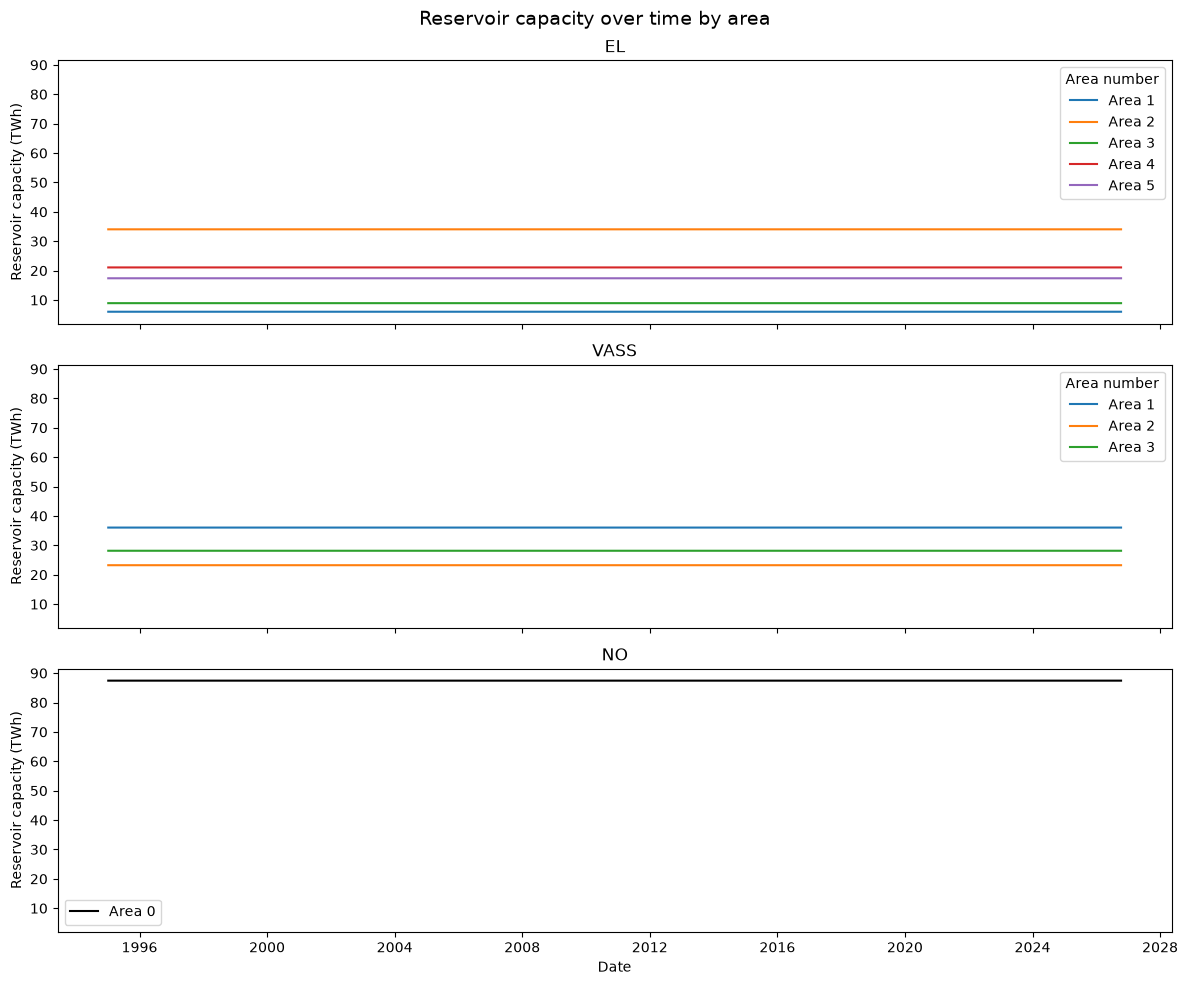

In [15]:
plot_by_area(df, "reservoir_capacity_twh", "Reservoir capacity (TWh)", "Reservoir capacity over time by area")

As in Part 1, reservoir capacity remains nearly constant within each area, and the relative differences in capacity between areas are unchanged.

##### `stored_energy_twh`

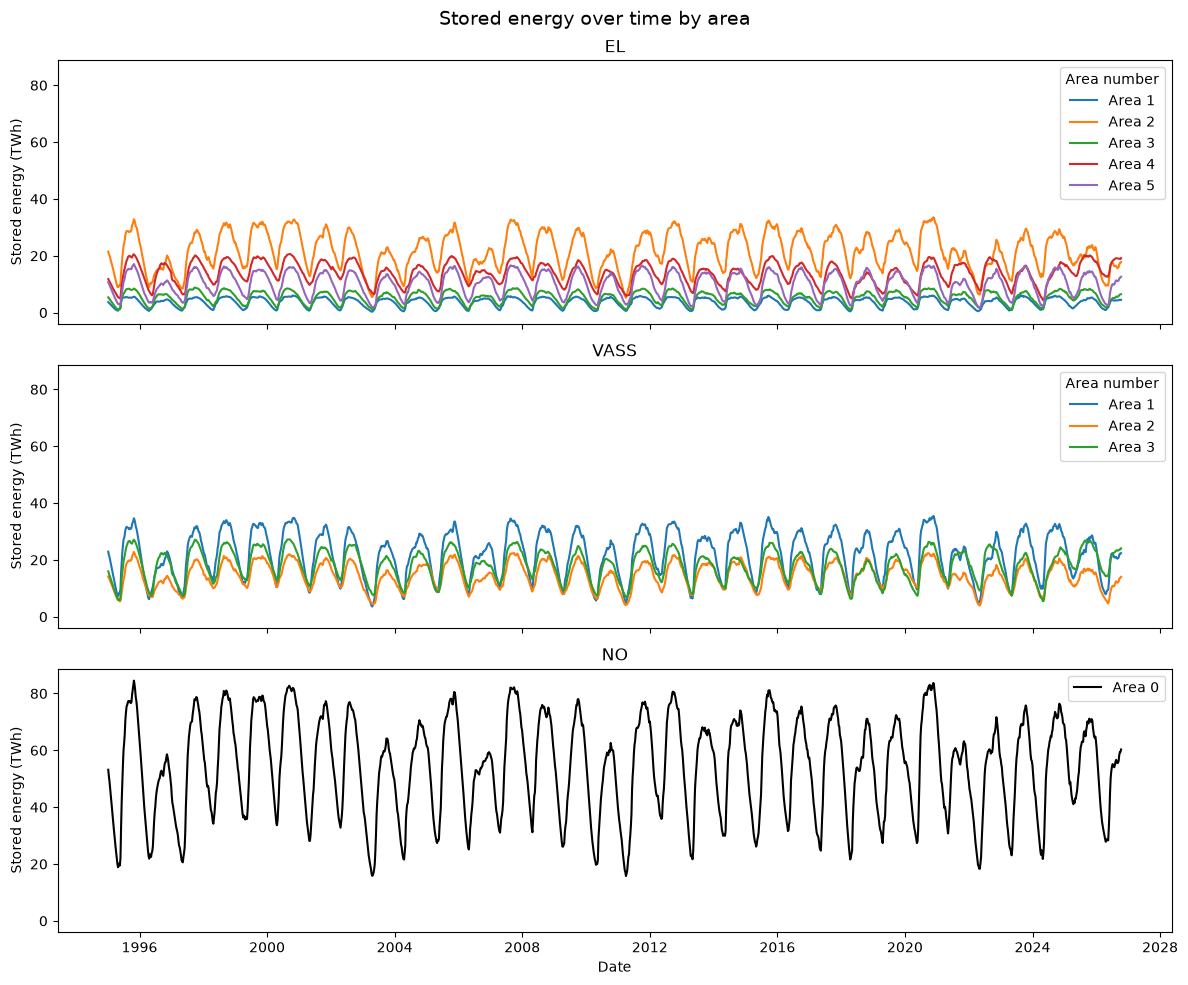

In [16]:
plot_by_area(df, "stored_energy_twh", "Stored energy (TWh)", "Stored energy over time by area")

The stored-energy series reproduces the same area differences and seasonal variation observed in Part 1, now including the latest API observations.

##### `next_publication_date`

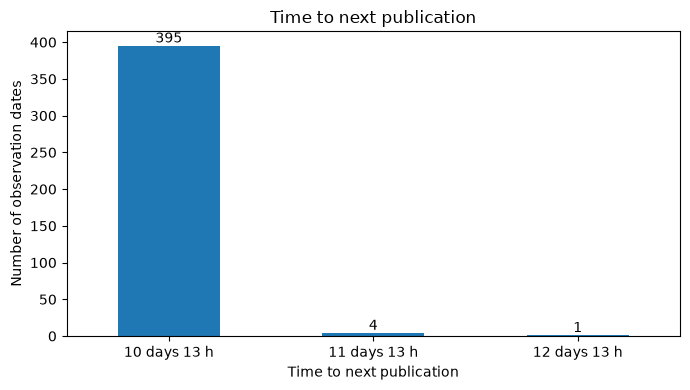

In [17]:
# Prepare one valid publication date for each observation date
publication_data = (df[df["next_publication_date"] != "0001-01-01T00:00:00"]
                    [["date_id", "next_publication_date"]].drop_duplicates().copy())

# Convert publication dates to datetime
publication_data["next_publication_date"] = pd.to_datetime(
    publication_data["next_publication_date"])

# Calculate the publication delay in whole hours
publication_data["publication_delay_hours"] = (
    publication_data["next_publication_date"] - publication_data["date_id"]
    ).dt.total_seconds().div(3600).round().astype(int)

# Create readable labels for the observed delays
publication_data["publication_delay"] = publication_data[
    "publication_delay_hours"].apply(
        lambda hours: f"{hours // 24} days {hours % 24} h")

# Count each publication delay
delay_counts = (publication_data.groupby(["publication_delay_hours", "publication_delay"])
                .size().sort_index())

# Plot the publication-delay frequencies
ax = delay_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Time to next publication")
plt.xlabel("Time to next publication")
plt.ylabel("Number of observation dates")
plt.xticks(range(len(delay_counts)),
           [label for _, label in delay_counts.index], rotation=0)

# Display the exact count above each bar
for i, count in enumerate(delay_counts):
    ax.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()

The publication delay pattern remains almost identical to Part 1, but the additional API observations increase the number of dates with the most common delay.

##### `previous_week_reservoir_fill_ratio`

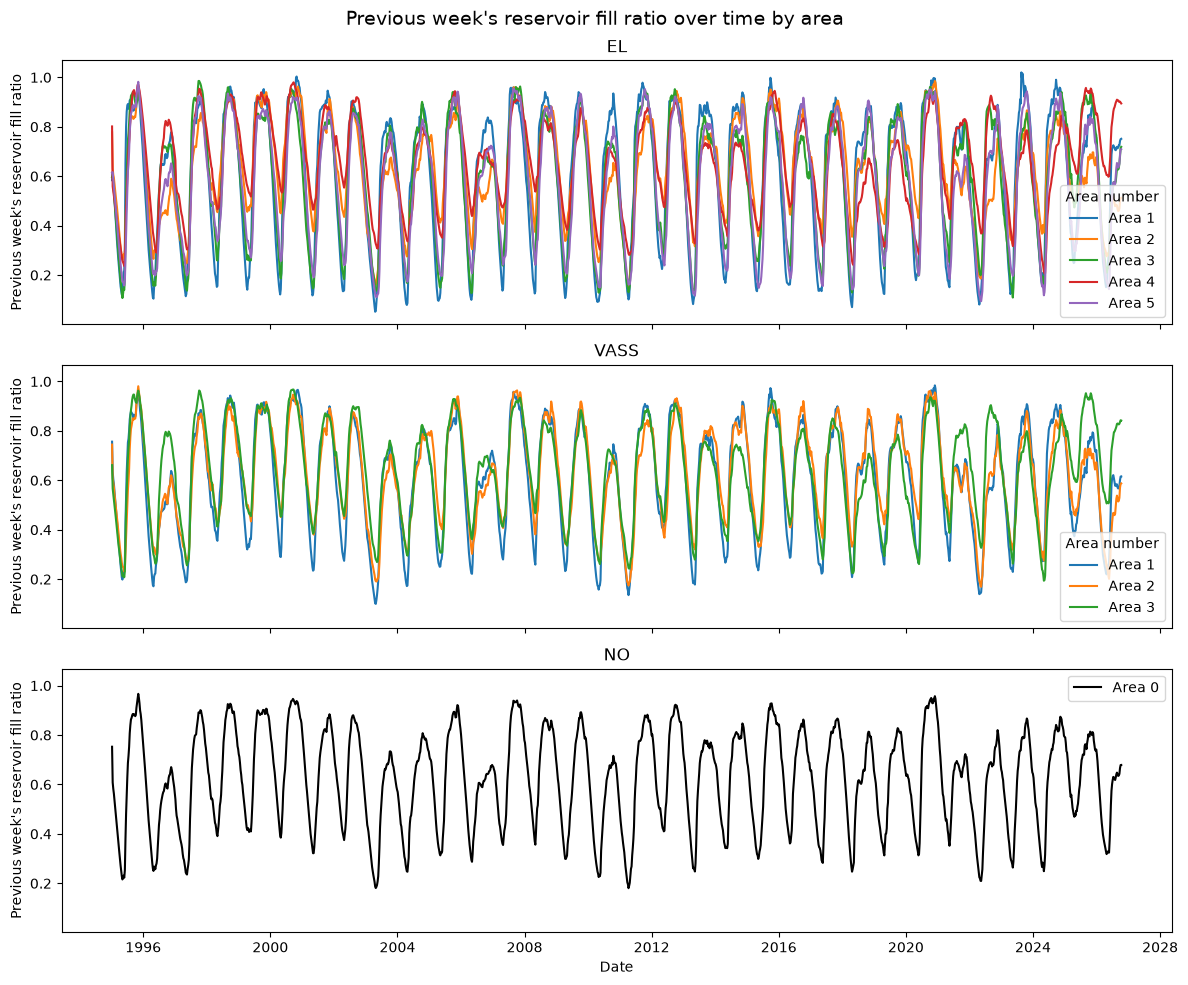

In [18]:
plot_by_area(df, "previous_week_reservoir_fill_ratio", "Previous week's reservoir fill ratio", "Previous week's reservoir fill ratio over time by area")

The previous-week fill ratios show the same behaviour as in Part 1 and continue to closely follow the current fill-ratio series.

##### `reservoir_fill_ratio_change`

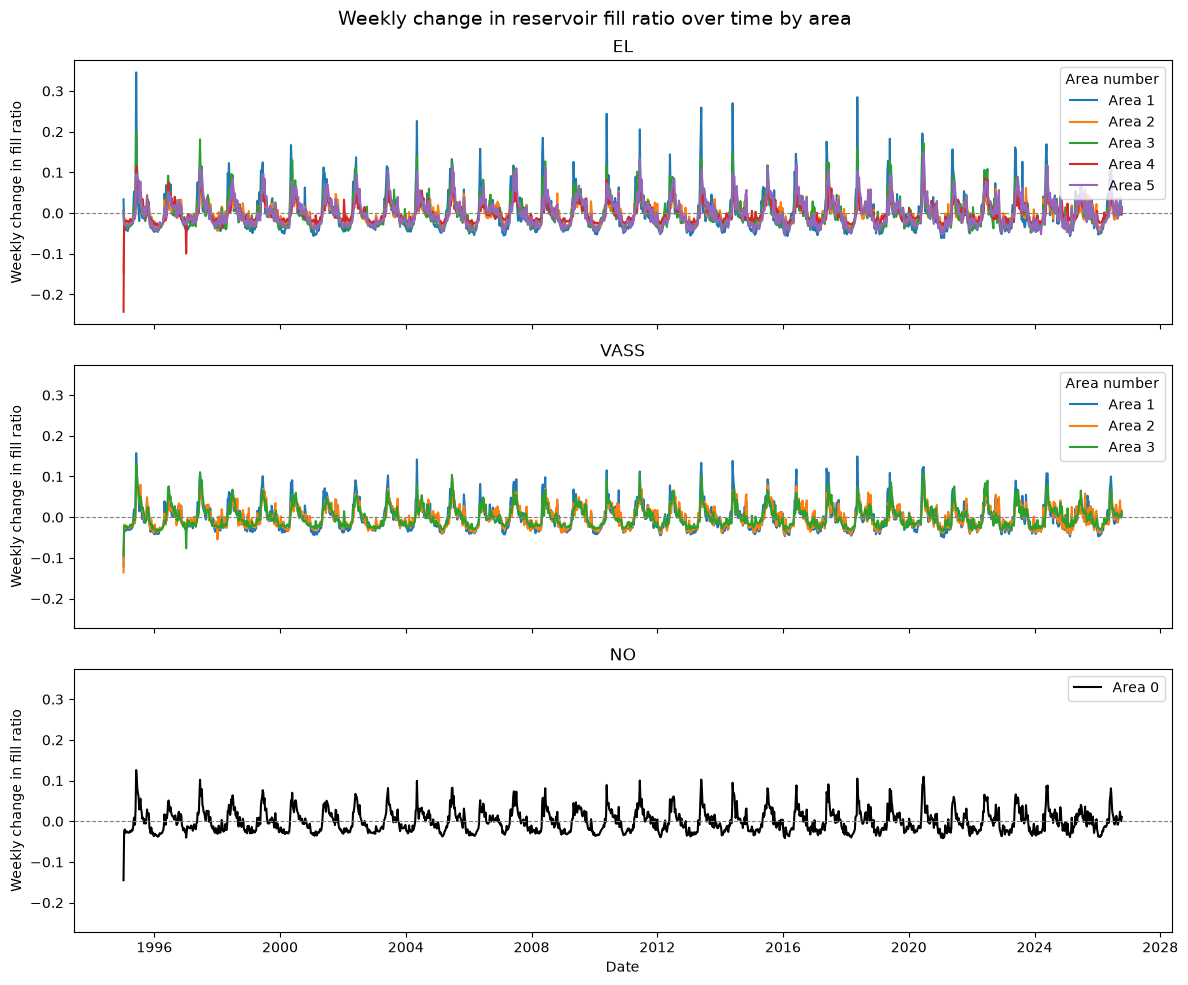

In [19]:
plot_by_area(df, "reservoir_fill_ratio_change", "Weekly change in fill ratio", "Weekly change in reservoir fill ratio over time by area", zero_line=True)

The weekly changes remain centred around zero with alternating periods of filling and depletion, consistent with the pattern seen in Part 1.

#### Combined plot

<div class="alert alert-block alert-info">
<b>Plotting choice:</b> The <code>NO 0</code> series is used to keep the combined plot readable. An alternative would be to plot the combined measurements for all nine area combinations in a 3 × 3 subplot layout, but this would be more crowded and would largely repeat the area-specific visualisations in Section 1.4.
</div>

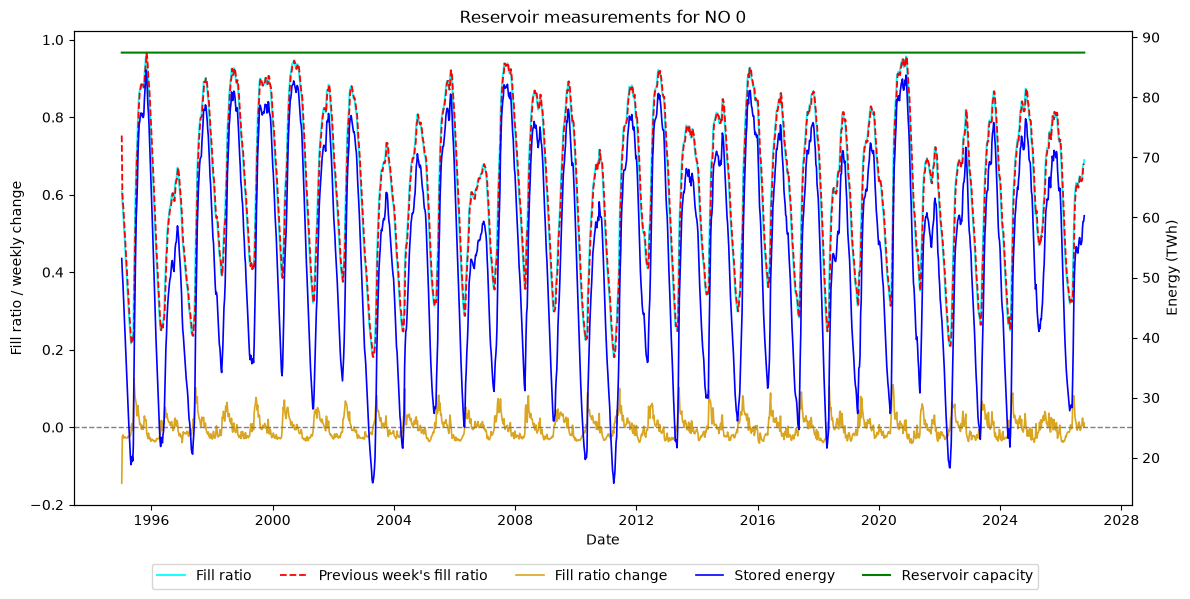

In [20]:
# Select the NO 0 time series and sort it chronologically
combined_data = (df[(df["area_type"] == "NO") & (df["area_number"] == 0)].sort_values("date_id"))

# Create a figure with two y-axes
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

# Fill-related variables: left y-axis
ax1.plot(combined_data["date_id"], combined_data["reservoir_fill_ratio"], label="Fill ratio",
         color="cyan", linewidth=1.3)

ax1.plot(combined_data["date_id"], combined_data["previous_week_reservoir_fill_ratio"],
         label="Previous week's fill ratio", color="red", linewidth=1.3, linestyle="--")

ax1.plot(combined_data["date_id"], combined_data["reservoir_fill_ratio_change"],
         label="Fill ratio change", color="goldenrod", linewidth=1.2)

# Add a reference line for positive and negative weekly change
ax1.axhline(y=0, color="gray", linestyle="--", linewidth=1)

# Energy-related variables: right y-axis
ax2.plot(combined_data["date_id"], combined_data["stored_energy_twh"],
         label="Stored energy", color="blue", linewidth=1.2)

ax2.plot(combined_data["date_id"], combined_data["reservoir_capacity_twh"],
         label="Reservoir capacity", color="green", linewidth=1.5)

# Title and axis labels
ax1.set_title("Reservoir measurements for NO 0")
ax1.set_xlabel("Date")
ax1.set_ylabel("Fill ratio / weekly change")
ax2.set_ylabel("Energy (TWh)")

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

fig.legend(lines1 + lines2, labels1 + labels2, loc="lower center", ncol=5,
           bbox_to_anchor=(0.5, -0.002), frameon=True)

# Leave space for the legend
plt.tight_layout()
plt.subplots_adjust(bottom=0.15)

plt.show()

The combined plot reproduces the Part 1 visualisation using the API data. The overall relationships between the five reservoir variables remain unchanged.

## 2. Cross-border transfer data

### 2.1 ENTSO-E API connection

Cross-border electricity transfer data are retrieved from the [ENTSO-E Transparency Platform](https://transparency.entsoe.eu) using the [ENTSO-E API](https://documenter.getpostman.com/view/7009892/2s93JtP3F6). Access to the API requires a security token obtained through an ENTSO-E account.

The security token is stored in a local `.env` file that is excluded from Git and loaded into the notebook as an environment variable.

To verify the ENTSO-E API setup, I retrieve 30 minutes of physical flow data from DK1 to NO2 on 10 October 2026 using the 12.1.G Cross-Border Physical Flows request (`documentType=A11`). I then compare the returned values with the Transparency Platform, taking into account that the API timestamps are in UTC while the website displays CEST.

In [21]:
# Define the ENTSO-E endpoint and EIC codes for the test connection
entsoe_url = "https://web-api.tp.entsoe.eu/api"

test_eic_codes = {"BZN|NO2": "10YNO-2--------T",
                  "BZN|DK1": "10YDK-1--------W"}

# Request physical flow from DK1 to NO2 from 00:00 to 00:30 UTC on 10 October 2026
params = {"securityToken": entsoe_token,
          "documentType": "A11",
          "in_Domain": test_eic_codes["BZN|NO2"],
          "out_Domain": test_eic_codes["BZN|DK1"],
          "periodStart": "202610100000",
          "periodEnd": "202610100030"}

# Send the request and raise an exception if it fails
response = requests.get(entsoe_url, params=params, timeout=60)
response.raise_for_status()

print(response.text)

<?xml version="1.0" encoding="utf-8"?>
<Publication_MarketDocument xmlns="urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0">
  <mRID>d1502402833e4cc09dbe5636e5f71f5c</mRID>
  <revisionNumber>1</revisionNumber>
  <type>A11</type>
  <sender_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</sender_MarketParticipant.mRID>
  <sender_MarketParticipant.marketRole.type>A32</sender_MarketParticipant.marketRole.type>
  <receiver_MarketParticipant.mRID codingScheme="A01">10X1001A1001A450</receiver_MarketParticipant.mRID>
  <receiver_MarketParticipant.marketRole.type>A33</receiver_MarketParticipant.marketRole.type>
  <createdDateTime>2026-10-17T14:04:52Z</createdDateTime>
  <period.timeInterval>
    <start>2026-10-10T00:00Z</start>
    <end>2026-10-10T00:30Z</end>
  </period.timeInterval>
    <TimeSeries>
      <mRID>1</mRID>
      <businessType>A66</businessType>
      <in_Domain.mRID codingScheme="A01">10YNO-2--------T</in_Domain.mRID>
      <out_Domain.mRID codingScheme="A01">1

The API response is XML. It contains the flow direction, time interval, resolution and the measured values.

For this test, the API returned 996.365354 MW and 1060.557271 MW for 00:00–00:30 UTC. This corresponds to 02:00–02:30 CEST, where the Transparency Platform shows 996.37 MW and 1060.56 MW. The XML is parsed in the next section.

### 2.2 Retrieve two years of cross-border transfer data

For the full dataset, I identified nine international bidding-zone connections involving Norway in the ENTSO-E Transparency Platform. Physical flow data are retrieved in both directions for each connection for the complete calendar years 2024 and 2025. Since the API allows a maximum of one year per request, the two-year period is split into two yearly intervals, giving 36 API requests in total.

The XML responses are converted to time-series observations and combined into one DataFrame. The requests use the A03 variable sized block representation, where unchanged values do not need to be repeated at every time step. These blocks are therefore expanded according to the resolution given for each period.

In [22]:
# Two one-year intervals in UTC, corresponding to midnight CET at the start and end of the Norwegian calendar years 2024 and 2025
periods = [("202312312300", "202412312300"),
           ("202412312300", "202512312300")]

# International bidding-zone connections involving Norway
connections = [("BZN|NO1", "BZN|SE3"),
               ("BZN|NO2", "BZN|DE-LU"),
               ("BZN|NO2", "BZN|DK1"),
               ("BZN|NO2", "BZN|GB"),
               ("BZN|NO2", "BZN|NL"),
               ("BZN|NO3", "BZN|SE2"),
               ("BZN|NO4", "BZN|FI"),
               ("BZN|NO4", "BZN|SE1"),
               ("BZN|NO4", "BZN|SE2")]

# EIC codes for the bidding zones used in the API requests (https://transparencyplatform.zendesk.com/hc/en-us/articles/15885757676308-Area-List-with-Energy-Identification-Code-EIC)
eic_codes = {"BZN|NO1": "10YNO-1--------2",
             "BZN|NO2": "10YNO-2--------T",
             "BZN|NO3": "10YNO-3--------J",
             "BZN|NO4": "10YNO-4--------9",
             "BZN|SE1": "10Y1001A1001A44P",
             "BZN|SE2": "10Y1001A1001A45N",
             "BZN|SE3": "10Y1001A1001A46L",
             "BZN|FI": "10YFI-1--------U",
             "BZN|DK1": "10YDK-1--------W",
             "BZN|DE-LU": "10Y1001A1001A82H",
             "BZN|GB": "10YGB----------A",
             "BZN|NL": "10YNL----------L"}

# Reverse mapping used to read the area names from the XML responses
eic_to_area = {code: area for area, code in eic_codes.items()}

In [23]:
def get_physical_flow(security_token, from_area, to_area, period_start, period_end):
    """Retrieve physical flow data for one direction and a specific time interval."""
    params = {"securityToken": security_token,
              "documentType": "A11",
              "out_Domain": eic_codes[from_area],
              "in_Domain": eic_codes[to_area],
              "periodStart": period_start,
              "periodEnd": period_end,
              "curveType": "A03"}

    response = requests.get(entsoe_url, params=params, timeout=60)
    response.raise_for_status()

    return response.content

In [24]:
def parse_physical_flow(xml_data):
    """Convert an ENTSO-E physical flow XML response to time-series observations."""

    # Parse the XML and create a short name for the ENTSO-E XML namespace
    root = ET.fromstring(xml_data)
    namespace = {"ns": root.tag.split("}")[0].strip("{")}

    rows = []
    
    # Process each time series contained in the response
    for time_series in root.findall("ns:TimeSeries", namespace):

        # Read the EIC codes for the exporting and importing areas
        from_code = time_series.find("ns:out_Domain.mRID", namespace).text
        to_code = time_series.find("ns:in_Domain.mRID", namespace).text

        # Convert the EIC codes back to the bidding-zone names used in the project
        from_area = eic_to_area[from_code]
        to_area = eic_to_area[to_code]
        
        # Process each period returned for the time series
        for period in time_series.findall("ns:Period", namespace):

            # Read when the period starts and ends
            start = pd.Timestamp(period.find("ns:timeInterval/ns:start", namespace).text)
            end = pd.Timestamp(period.find("ns:timeInterval/ns:end", namespace).text)

            # Convert the ISO duration (e.g. PT15M) to a timedelta and also store it as minutes
            resolution = pd.to_timedelta(period.find("ns:resolution", namespace).text)
            resolution_minutes = int(resolution.total_seconds() / 60)

            # In A03, a point gives a new value starting at its position. The same value continues until another point is reported.
            changes = {int(point.find("ns:position", namespace).text): float(point.find("ns:quantity", namespace).text) for point in period.findall("ns:Point", namespace)}

            # Position 1 is needed to know the value at the start of the period
            if 1 not in changes:
                raise ValueError("Expected an A03 value at position 1.")

            # Calculate how many regular intervals belong to this period
            n_intervals = int((end - start) / resolution)
            current_value = changes[1]

            # Expand the A03 blocks to one observation for every time interval
            for position in range(1, n_intervals + 1):

                # Update the value only when A03 reports a new point
                if position in changes:
                    current_value = changes[position]

                # The first position starts at the beginning of the period, so each timestamp is shifted by position - 1 intervals
                rows.append({"timestamp": start + (position - 1) * resolution,
                             "from_area": from_area,
                             "to_area": to_area,
                             "resolution_minutes": resolution_minutes,
                             "flow_mw": current_value})

    return pd.DataFrame(rows)

In [25]:
# Retrieve both directions for every connection and yearly period
flow_frames = []

for norway_area, foreign_area in connections:
    for from_area, to_area in [(norway_area, foreign_area), (foreign_area, norway_area)]:
        for period_start, period_end in periods:
            xml_data = get_physical_flow(entsoe_token, from_area, to_area, period_start, period_end)

            # Convert the ENTSO-E XML response to tabular observations
            flow_df = parse_physical_flow(xml_data)

            if flow_df.empty:
                raise ValueError(f"No data returned for {from_area} → {to_area}, {period_start}–{period_end}")

            flow_frames.append(flow_df)

# Combine all API responses into one dataset
cross_border_df = pd.concat(flow_frames, ignore_index=True)

cross_border_df.head()

,timestamp,from_area,to_area,resolution_minutes,flow_mw
0,2023-12-31 23:00:00+00:00,BZN|NO1,BZN|SE3,60,0.0
1,2024-01-01 00:00:00+00:00,BZN|NO1,BZN|SE3,60,0.0
2,2024-01-01 01:00:00+00:00,BZN|NO1,BZN|SE3,60,0.0
3,2024-01-01 02:00:00+00:00,BZN|NO1,BZN|SE3,60,0.0
4,2024-01-01 03:00:00+00:00,BZN|NO1,BZN|SE3,60,0.0


In [26]:
# Check the final dataset structure and confirm all directional pairs are present
cross_border_df.info()
cross_border_df[["from_area", "to_area"]].drop_duplicates().sort_values(["from_area", "to_area"]).reset_index(drop=True)

<class 'pandas.DataFrame'>
RangeIndex: 788928 entries, 0 to 788927
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   timestamp           788928 non-null  datetime64[us, UTC]
 1   from_area           788928 non-null  str                
 2   to_area             788928 non-null  str                
 3   resolution_minutes  788928 non-null  int64              
 4   flow_mw             788928 non-null  float64            
dtypes: datetime64[us, UTC](1), float64(1), int64(1), str(2)
memory usage: 40.5 MB


,from_area,to_area
0,BZN|DE-LU,BZN|NO2
1,BZN|DK1,BZN|NO2
2,BZN|FI,BZN|NO4
3,BZN|GB,BZN|NO2
4,BZN|NL,BZN|NO2
5,BZN|NO1,BZN|SE3
6,BZN|NO2,BZN|DE-LU
7,BZN|NO2,BZN|DK1
8,BZN|NO2,BZN|GB
9,BZN|NO2,BZN|NL


The combined dataset contains all 18 directional pairs corresponding to the nine international connections in both directions, and the retrieved observations contain no missing values.

The ENTSO-E timestamps are in UTC, while the flow values are given as power in MW. The time resolution of each observation therefore has to be taken into account when total transferred energy is calculated later.

### 2.3 Store data in Cassandra with Spark

Cassandra runs locally in Docker on port 9042. I set up a separate keyspace and table for the project, then used Spark to write the cross-border data to Cassandra and read it back.

In [27]:
# Connect to the local Cassandra instance
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

# Create a keyspace for the project
session.execute("""CREATE KEYSPACE IF NOT EXISTS ind320_project
                WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};""")
session.set_keyspace("ind320_project")

In [28]:
# Create a local Spark session configured to connect to Cassandra
spark = SparkSession.builder.appName("IND320-SparkCassandra").\
    config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1").\
    config("spark.cassandra.connection.host", "localhost").\
    config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions").\
    config("spark.sql.catalog.mycatalog", "com.datastax.spark.connector.datasource.CassandraCatalog").\
    config("spark.cassandra.connection.port", "9042").getOrCreate()
    
spark.sparkContext.setLogLevel("ERROR")

26/10/17 16:08:17 WARN Utils: Your hostname, Katarzynas-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.1.180 instead (on interface en0)
26/10/17 16:08:17 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/kahaland/.ivy2/cache
The jars for the packages stored in: /Users/kahaland/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-68b55998-601b-4d04-9f62-0bc4ded3f322;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central


:: loading settings :: url = jar:file:/Users/kahaland/Desktop/IND320-kahaland/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassandra#java-driver-query-builder;4.18.1 in central
	found org.apache.commons#commons-lang3;3.10 in central
	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found org.scala-lang#scala-reflect;2.12.19 in central
:: resolution report :: resolve 168ms :: artifacts dl 6ms
	:: modules in use:
	com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 from central in [default]
	com.datastax.oss#native-protocol;1.5.1 from central in [default]
	com.datastax.spark#spark-cassandra-connector-dr

In [29]:
# Create a clean table for the ENTSO-E cross-border observations
session.execute("DROP TABLE IF EXISTS cross_border_flows;")

session.execute("""CREATE TABLE cross_border_flows (
                    timestamp timestamp,
                    from_area text,
                    to_area text,
                    resolution_minutes int,
                    flow_mw double,
                    PRIMARY KEY ((from_area, to_area), timestamp));""")

In [30]:
# ENTSO-E timestamps are in UTC. Converting the pandas timestamps directly to Spark gave duplicate times around the daylight saving transition
# https://stackoverflow.com/questions/74579515/spark-createdataframe-changes-the-date-value-in-column-with-type-datetime64ns
spark.conf.set("spark.sql.session.timeZone", "UTC")

# Keep the UTC offset explicitly while transferring the timestamps from pandas to Spark
spark_input_df = cross_border_df.copy()
spark_input_df["timestamp"] = spark_input_df["timestamp"].dt.strftime("%Y-%m-%dT%H:%M:%S%z") # %z gives an offset like +0000

flow_spark_df = spark.createDataFrame(spark_input_df)

# Parse the strings with their timezone offset back to Spark timestamps
# https://stackoverflow.com/questions/66238569/convert-string-with-utc-offset-to-spark-timestamp
flow_spark_df = flow_spark_df.withColumn("timestamp", F.to_timestamp("timestamp", "yyyy-MM-dd'T'HH:mm:ssZ")) # Spark uses Z for offsets like +0000

# pandas int64 becomes Spark long, but int is sufficient for the small resolution values
flow_spark_df = flow_spark_df.withColumn("resolution_minutes", flow_spark_df["resolution_minutes"].cast("int"))

flow_spark_df.printSchema()
flow_spark_df.show(5, truncate=False)

root
 |-- timestamp: timestamp (nullable = true)
 |-- from_area: string (nullable = true)
 |-- to_area: string (nullable = true)
 |-- resolution_minutes: integer (nullable = true)
 |-- flow_mw: double (nullable = true)



+-------------------+---------+-------+------------------+-------+
|timestamp          |from_area|to_area|resolution_minutes|flow_mw|
+-------------------+---------+-------+------------------+-------+
|2023-12-31 23:00:00|BZN|NO1  |BZN|SE3|60                |0.0    |
|2024-01-01 00:00:00|BZN|NO1  |BZN|SE3|60                |0.0    |
|2024-01-01 01:00:00|BZN|NO1  |BZN|SE3|60                |0.0    |
|2024-01-01 02:00:00|BZN|NO1  |BZN|SE3|60                |0.0    |
|2024-01-01 03:00:00|BZN|NO1  |BZN|SE3|60                |0.0    |
+-------------------+---------+-------+------------------+-------+
only showing top 5 rows



In [31]:
# Check that the Cassandra primary key is unique before storing the data
duplicate_keys = (flow_spark_df.groupBy("from_area", "to_area", "timestamp").count().filter("count > 1"))

print("Duplicate keys:", duplicate_keys.count())

Duplicate keys: 0


In [32]:
# Store the ENTSO-E observations in Cassandra using Spark
flow_spark_df.write.format("org.apache.spark.sql.cassandra").options(table="cross_border_flows", keyspace="ind320_project").mode("append").save()

In [33]:
# Read the stored observations back from Cassandra
cassandra_df = spark.read.format("org.apache.spark.sql.cassandra").options(table="cross_border_flows", keyspace="ind320_project").load()

cassandra_df.printSchema()
cassandra_df.show(5, truncate=False)

# Check that all observations were stored
print("Rows:", cassandra_df.count())
print("Directional pairs:", cassandra_df.select("from_area", "to_area").distinct().count())

root
 |-- from_area: string (nullable = false)
 |-- to_area: string (nullable = false)
 |-- timestamp: timestamp (nullable = true)
 |-- flow_mw: double (nullable = true)
 |-- resolution_minutes: integer (nullable = true)

+---------+---------+-------------------+-------+------------------+
|from_area|to_area  |timestamp          |flow_mw|resolution_minutes|
+---------+---------+-------------------+-------+------------------+
|BZN|NO2  |BZN|DE-LU|2023-12-31 23:00:00|0.0    |15                |
|BZN|NO2  |BZN|DE-LU|2023-12-31 23:15:00|0.0    |15                |
|BZN|NO2  |BZN|DE-LU|2023-12-31 23:30:00|0.0    |15                |
|BZN|NO2  |BZN|DE-LU|2023-12-31 23:45:00|0.0    |15                |
|BZN|NO2  |BZN|DE-LU|2024-01-01 00:00:00|0.0    |15                |
+---------+---------+-------------------+-------+------------------+
only showing top 5 rows

Rows: 788928
Directional pairs: 18


The Cassandra check shows that all 788 928 observations were stored successfully, covering both directions for all nine connections.

### 2.4 Extract relevant data from Cassandra with Spark

After the Cassandra table is read into Spark, a temporary view is created and queried with Spark SQL to keep the information needed for the plots.

In [34]:
# Create a temporary view for querying the Cassandra data with Spark SQL
cassandra_df.createOrReplaceTempView("cross_border_flows_view")

# Identify the Norwegian and foreign areas and whether the flow is into or out of Norway
cross_border_spark_df = spark.sql("""
    SELECT
        timestamp,
        flow_mw,
        flow_mw * resolution_minutes / 60.0 AS energy_mwh,
        CASE
            WHEN from_area LIKE 'BZN|NO%' THEN from_area
            ELSE to_area
        END AS norway_area,
        CASE
            WHEN from_area LIKE 'BZN|NO%' THEN to_area
            ELSE from_area
        END AS foreign_area,
        CASE
            WHEN from_area LIKE 'BZN|NO%' THEN 'out'
            ELSE 'in'
        END AS direction
    FROM cross_border_flows_view
""")

cross_border_spark_df.show(10)

+-------------------+-------+----------+-----------+------------+---------+
|          timestamp|flow_mw|energy_mwh|norway_area|foreign_area|direction|
+-------------------+-------+----------+-----------+------------+---------+
|2023-12-31 23:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 00:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 01:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 02:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 03:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 04:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 05:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 06:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 07:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
|2024-01-01 08:00:00|    0.0|       0.0|    BZN|NO3|     BZN|SE2|      out|
+-----------

In [35]:
# Check the prepared data before plotting
print("Rows:", cross_border_spark_df.count())
print("Connections:", cross_border_spark_df.select("norway_area", "foreign_area").distinct().count())
print("Directions:", cross_border_spark_df.select("direction").distinct().count())

missing = cross_border_spark_df.filter("""timestamp IS NULL OR
                                       flow_mw IS NULL OR
                                       energy_mwh IS NULL OR
                                       norway_area IS NULL OR
                                       foreign_area IS NULL OR
                                       direction IS NULL""").count()

print("Rows with missing values:", missing)

Rows: 788928
Connections: 9
Directions: 2
Rows with missing values: 0


In [36]:
# Check that both directions are present for all nine connections
cross_border_spark_df.select("norway_area", "foreign_area", "direction").distinct().orderBy(
    "norway_area", "foreign_area", "direction").show()

+-----------+------------+---------+
|norway_area|foreign_area|direction|
+-----------+------------+---------+
|    BZN|NO1|     BZN|SE3|       in|
|    BZN|NO1|     BZN|SE3|      out|
|    BZN|NO2|   BZN|DE-LU|       in|
|    BZN|NO2|   BZN|DE-LU|      out|
|    BZN|NO2|     BZN|DK1|       in|
|    BZN|NO2|     BZN|DK1|      out|
|    BZN|NO2|      BZN|GB|       in|
|    BZN|NO2|      BZN|GB|      out|
|    BZN|NO2|      BZN|NL|       in|
|    BZN|NO2|      BZN|NL|      out|
|    BZN|NO3|     BZN|SE2|       in|
|    BZN|NO3|     BZN|SE2|      out|
|    BZN|NO4|      BZN|FI|       in|
|    BZN|NO4|      BZN|FI|      out|
|    BZN|NO4|     BZN|SE1|       in|
|    BZN|NO4|     BZN|SE1|      out|
|    BZN|NO4|     BZN|SE2|       in|
|    BZN|NO4|     BZN|SE2|      out|
+-----------+------------+---------+



The Spark SQL query keeps the data needed for the plots and derives `norway_area`, `foreign_area`, `direction` and `energy_mwh`. The first three identify the connection and whether the flow goes into or out of Norway. `energy_mwh` is calculated from `flow_mw` and the length of each interval so that the transferred energy can be summed correctly. The checks show that all 788 928 observations are still present, with nine connections, both directions and no missing values.

### 2.5 Cross-border transfer plots

#### 2.5.1 Yearly transfer by direction

The NO2-DK1 connection is used to compare the total energy transferred into and out of Norway in 2025.

In [37]:
selected_year = 2025
selected_norway_area = "BZN|NO2"
selected_foreign_area = "BZN|DK1"

norway_area = selected_norway_area.replace("BZN|", "")
foreign_area = selected_foreign_area.replace("BZN|", "")

# Use Norwegian local time only to identify the calendar year (the stored UTC timestamp is unchanged)
timestamp_no = F.from_utc_timestamp("timestamp", "Europe/Oslo")

# Filter the selected connection and year, then sum transferred energy by direction
yearly_transfer_df = (cross_border_spark_df.filter((F.col("norway_area") == selected_norway_area) & (F.col("foreign_area") == selected_foreign_area) & (F.year(timestamp_no) == selected_year))
                      .groupBy("direction").agg(F.sum("energy_mwh").alias("energy_mwh")).orderBy("direction"))


yearly_transfer_df.show()

+---------+------------------+
|direction|        energy_mwh|
+---------+------------------+
|       in|1153915.0300735037|
|      out| 8157330.694999969|
+---------+------------------+



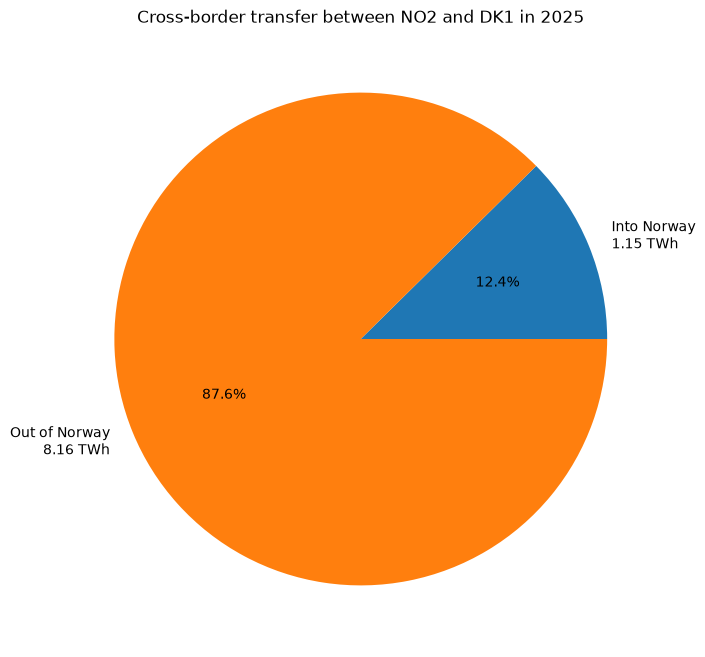

In [38]:
yearly_transfer_pd = yearly_transfer_df.toPandas()

# Convert MWh to TWh for more readable labels
yearly_transfer_pd["energy_twh"] = yearly_transfer_pd["energy_mwh"] / 1_000_000

direction_labels = yearly_transfer_pd["direction"].map({"in": "Into Norway",
                                                        "out": "Out of Norway"})

labels = [f"{direction}\n{energy:.2f} TWh" for direction, energy in zip(direction_labels, yearly_transfer_pd["energy_twh"])]

plt.figure(figsize=(8, 8))
plt.pie(yearly_transfer_pd["energy_twh"], labels=labels, autopct="%1.1f%%")
plt.title(f"Cross-border transfer between {norway_area} and {foreign_area} in {selected_year}")
plt.show()

In 2025, most of the energy transferred between NO2 and DK1 went out of Norway. About 8.16 TWh (87.6%) was transferred out, compared with 1.15 TWh (12.4%) into Norway.

#### 2.5.2 Monthly cross-border flow

The same NO2-DK1 connection is used to show the physical flow into and out of Norway during January 2025.

In [39]:
selected_month = 1

# Use Norwegian local time to identify the calendar month
monthly_flow_df = cross_border_spark_df.filter((F.col("norway_area") == selected_norway_area) &
                                               (F.col("foreign_area") == selected_foreign_area) &
                                               (F.year(timestamp_no) == selected_year) &
                                               (F.month(timestamp_no) == selected_month))

monthly_flow_df.select("timestamp", "direction", "flow_mw").show()

+-------------------+---------+-------+
|          timestamp|direction|flow_mw|
+-------------------+---------+-------+
|2024-12-31 23:00:00|      out|    0.0|
|2025-01-01 00:00:00|      out|    0.0|
|2025-01-01 01:00:00|      out|    0.0|
|2025-01-01 02:00:00|      out|    0.0|
|2025-01-01 03:00:00|      out|    0.0|
|2025-01-01 04:00:00|      out|    0.0|
|2025-01-01 05:00:00|      out|    0.0|
|2025-01-01 06:00:00|      out|    0.0|
|2025-01-01 07:00:00|      out|    0.0|
|2025-01-01 08:00:00|      out|    0.0|
|2025-01-01 09:00:00|      out|    0.0|
|2025-01-01 10:00:00|      out|    0.0|
|2025-01-01 11:00:00|      out|    0.0|
|2025-01-01 12:00:00|      out|    0.0|
|2025-01-01 13:00:00|      out|    0.0|
|2025-01-01 14:00:00|      out|    0.0|
|2025-01-01 15:00:00|      out|    0.0|
|2025-01-01 16:00:00|      out|    0.0|
|2025-01-01 17:00:00|      out|    0.0|
|2025-01-01 18:00:00|      out|    0.0|
+-------------------+---------+-------+
only showing top 20 rows



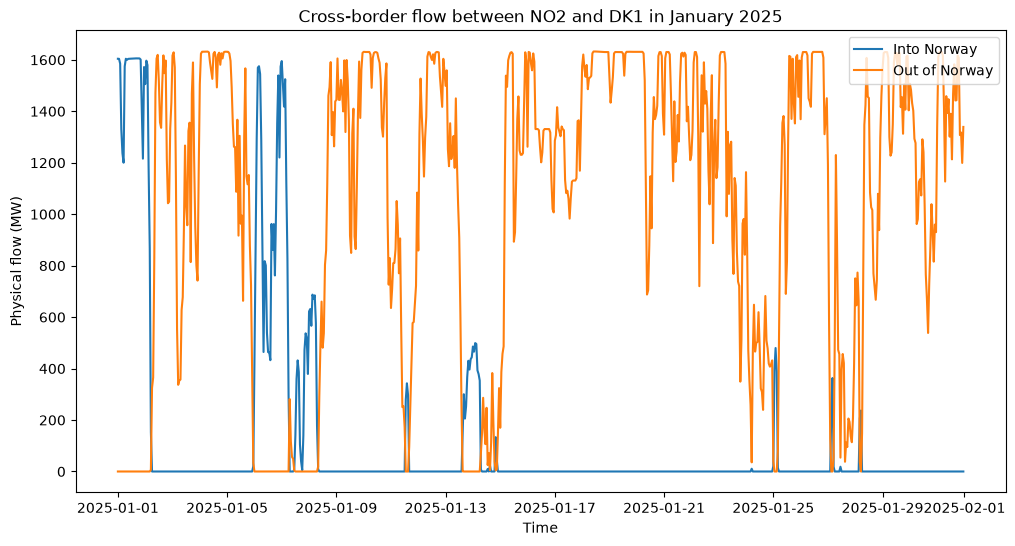

In [40]:
monthly_flow_pd = monthly_flow_df.select("timestamp", "direction", "flow_mw").toPandas()

# Convert the stored UTC timestamps to Norwegian local time for plotting
monthly_flow_pd["timestamp"] = (pd.to_datetime(monthly_flow_pd["timestamp"], utc=True).dt.tz_convert("Europe/Oslo"))

monthly_flow_pd = monthly_flow_pd.sort_values("timestamp")

plt.figure(figsize=(12, 6))

for direction, label in [("in", "Into Norway"), ("out", "Out of Norway")]:
    data = monthly_flow_pd[monthly_flow_pd["direction"] == direction]
    plt.plot(data["timestamp"], data["flow_mw"], label=label)

plt.xlabel("Time")
plt.ylabel("Physical flow (MW)")
plt.title(f"Cross-border flow between {norway_area} and {foreign_area} in January {selected_year}")
plt.legend(loc="upper right")
plt.show()

In January 2025, most of the flow between NO2 and DK1 went out of Norway. There were also shorter periods with flow into Norway.

## 4. Streamlit App

The Streamlit app was updated to retrieve the reservoir data directly from the NVE Magasinstatistikk API instead of the local CSV file. Data loading is still handled by the shared `load_data()` function, so the existing reservoir pages can use the new data source without changing how they access the data.

In [41]:
!cat ../modules/data.py

import pandas as pd
import requests
import streamlit as st


@st.cache_data
def load_data():
    """Retrieve, prepare and cache the NVE Magasinstatistikk reservoir dataset."""
    url = ("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData")
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    df = pd.DataFrame(response.json())

    # Rename the original column headers to English names
    df = df.rename(columns={
        "dato_Id": "date_id",
        "omrType": "area_type",
        "omrnr": "area_number",
        "iso_aar": "iso_year",
        "iso_uke": "iso_week",
        "fyllingsgrad": "reservoir_fill_ratio",
        "kapasitet_TWh": "reservoir_capacity_twh",
        "fylling_TWh": "stored_energy_twh",
        "neste_Publiseringsdato": "next_publication_date",
        "fyllingsgrad_forrige_uke": "previous_week_reservoir_fill_ratio",
        "endring_fyllingsgrad": "reservoir_fill_ratio_change"
    })

    df["date_id"] = pd.t

### 4.1 Magasinstatistikk API page

The `HentOffentligData` endpoint returns the complete public reservoir dataset and does not accept query parameters. The dataset is therefore retrieved through the shared `load_data()` function and cached with `st.cache_data`. The same basic preprocessing as in Part 1 is retained, including renaming the columns to English.

A new Reservoir Fill Ratio page was added for exploring `reservoir_fill_ratio` (`fyllingsgrad` in the original Magasinstatistikk data). `st.radio` is used to select the area type (`EL`, `NO`, or `VASS`), and a date-range slider controls the period displayed. All area numbers belonging to the selected area type are plotted together. The selected area type and date range are stored in `st.session_state` so that the choices are preserved when moving between pages.

In [42]:
!cat ../pages/4_Reservoir_Fill_Ratio.py

import pandas as pd
import plotly.express as px
import streamlit as st

from modules.data import load_data


df = load_data()

st.title("Reservoir Fill Ratio")
st.write("Choose an area type and date range to view reservoir fill ratios over time.")

area_types = ["EL", "NO", "VASS"]

# Restore the previous area type
if "fill_area_type" not in st.session_state or st.session_state.fill_area_type not in area_types:
    st.session_state.fill_area_type = area_types[0]

selected_area_type = st.radio("Area type", area_types, index=area_types.index(st.session_state.fill_area_type), horizontal=True)
st.session_state.fill_area_type = selected_area_type

# Define the available date range
min_date = df["date_id"].min().date()
max_date = df["date_id"].max().date()

# Restore the previous date range
if "fill_date_range" not in st.session_state:
    st.session_state.fill_date_range = (min_date, max_date)

start_date, end_date = st.session_state.fill_date_range

# Reset the stored range if it is outsid

<div style="background-color:#EAF2F7; border-left:5px solid #3E7FA6; padding:12px 16px; border-radius:6px;">

<h2>AI usage</h2>

To be filled out

</div>

## Project log

I started Part 2 by exploring the Magasinstatistikk API from NVE in the Jupyter Notebook and comparing the returned data with the reservoir dataset from Part 1. The API returned the same overall structure, but included five additional weeks of observations. I also checked the geographical area definitions using the `HentOmråder` endpoint and compared them with the area combinations actually present in the reservoir data. Once I had confirmed how the API data was structured, I recreated the plots from Part 1 and checked that the main patterns were still the same.

I then updated the Streamlit app to use the NVE API instead of the local CSV file. Since both the Data Table and Data Plot pages already used the shared `load_data()` function, I did not need to rewrite the individual pages. The `HentOffentligData` endpoint returns the complete public dataset and does not accept query parameters, so I cache the downloaded data with `st.cache_data` and filter it later in the app. I keep the same basic preprocessing as in Part 1, including renaming the columns to English. After checking that the existing pages still worked correctly with the API data, I removed the old `reservoirs.csv` file from the project.

I also added a separate Reservoir Fill Ratio page to the Streamlit app. The page uses a radio button to select between `EL`, `NO`, and `VASS`, and a date-range slider to choose the period shown. Since the API does not support requesting a specific interval, the slider filters the cached dataset locally. For the selected area type, the fill ratios for all associated areas are plotted together. I also stored the selected area type and date range in `st.session_state` so that the selections are preserved when moving between pages.

For the ENTSO-E part, I retrieved physical flow data for the complete calendar years 2024 and 2025 for the nine international connections involving Norway. The data were downloaded in both directions and in yearly intervals because the API limits each request to one year. I also had to parse the XML responses and expand the A03 variable sized blocks into one observation per time interval. I checked the API values against the Transparency Platform before retrieving the full dataset.

I then set up Cassandra locally in Docker and used Spark to store the ENTSO-E data. I ran into a problem when converting the pandas timestamps directly to Spark, where times around the daylight saving transition were duplicated. This would have caused observations with the same Cassandra key to overwrite each other. I therefore kept the UTC offset explicitly during the pandas-to-Spark conversion and checked that the Cassandra key was unique before writing the data. I read the data back from Cassandra with Spark and confirmed that all 788 928 observations had been stored. After that, I used Spark SQL to keep the fields needed for the analysis and derive the Norwegian area, foreign area, direction and transferred energy. For the plots, I compared the yearly transfer into and out of Norway for NO2-DK1 and also looked at how the physical flow changed during January 2025.


To be filled out...